# 02 · Event-detection & possession evaluation (synthetic ground truth)

The analytics rules (possession, passes, shots, set pieces, fouls…) are evaluated on **synthetic matches**
that come with exact ground truth, so every rule change can be measured.
The generator reproduces single-camera failure modes: position jitter, ball dropouts & occlusions,
track-ID fragmentation and goalkeepers the colour clustering did not label.

Matching: predicted ↔ true events of the same type and team within ±2 s (±4 s for stoppage-based events).
For a real match, annotate events in a CSV (`t, type, team`) and use the same `evaluate_events`.

In [1]:
import sys, time, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 120)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
from football_eval.synthetic import SyntheticMatch, SynthConfig
from football_eval.config import load_config
from football_eval.analytics import run_analytics
from football_eval.evaluation import evaluate_events, possession_accuracy
TYPES = ["pass", "interception", "ball_recovery", "shot", "goal", "kickoff", "throw_in", "corner", "goal_kick", "free_kick", "foul"]

def run(seed=0, period_s=900, cfg=None, **noise):
    m = SyntheticMatch(SynthConfig(seed=seed, period_s=period_s, **noise)).generate()
    r = run_analytics(m["tracks"], m["ball"], cfg or load_config(), root=str(ROOT))
    return m, r

## 1 · One match in detail

In [2]:
t0 = time.time()
m, r = run(seed=0)
print(f"{len(m['tracks']):,} tracking rows, {len(m['gt_events'])} true events, analysed in {time.time()-t0:.1f}s")
ev_score = evaluate_events(r["events"], m["gt_events"], TYPES)
ev_score

404,967 tracking rows, 425 true events, analysed in 22.5s


,n_gt,n_pred,tp,precision,recall,f1
type,,,,,,
pass,259,258,253,0.981,0.977,0.979
interception,38,37,37,1.000,0.974,0.987
ball_recovery,22,19,17,0.895,0.773,0.829
shot,26,22,22,1.000,0.846,0.917
goal,5,5,5,1.000,1.000,1.000
kickoff,7,7,7,1.000,1.000,1.000
throw_in,21,22,21,0.955,1.000,0.977
corner,2,2,2,1.000,1.000,1.000
goal_kick,7,7,7,1.000,1.000,1.000


In [3]:
pa = possession_accuracy(r["fc"], r["possession"], m["truth"])
print({k: round(v, 3) for k, v in pa.items()})
gt = m["gt_events"]; ev = r["events"]
cmp = pd.DataFrame({
    "passes (true)": gt[gt.type == "pass"].groupby("team").size(),
    "passes (detected)": ev[ev.type == "pass"].groupby("team").size(),
    "completed (true)": gt[(gt.type == "pass") & (gt.outcome == "complete")].groupby("team").size(),
    "completed (detected)": ev[(ev.type == "pass") & (ev.outcome == "complete")].groupby("team").size(),
    "shots (true)": gt[gt.type == "shot"].groupby("team").size(),
    "shots (detected)": ev[ev.type == "shot"].groupby("team").size(),
    "goals (true)": gt[gt.type == "goal"].groupby("team").size(),
    "goals (detected)": ev[ev.type == "goal"].groupby("team").size(),
}).fillna(0).astype(int)
cmp.index = ["Team A", "Team B"][:len(cmp)]
cmp

{'frame_accuracy': 0.985, 'coverage': 0.949, 'team0_share_pred': 0.505, 'team0_share_gt': 0.501}


,passes (true),passes (detected),completed (true),completed (detected),shots (true),shots (detected),goals (true),goals (detected)
Team A,120,119,97,94,13,11,2,2
Team B,139,139,103,103,13,11,3,3


## 2 · Benchmark over several matches

In [4]:
rows = []
for seed in range(1, 5):
    m_, r_ = run(seed=seed, period_s=600)
    s = evaluate_events(r_["events"], m_["gt_events"], TYPES); s["seed"] = seed; rows.append(s.reset_index())
bench = pd.concat(rows)
agg = bench.groupby("type")[["n_gt", "tp", "n_pred"]].sum()
agg["precision"] = agg.tp / agg.n_pred; agg["recall"] = agg.tp / agg.n_gt
agg["f1"] = 2 * agg.precision * agg.recall / (agg.precision + agg.recall)
agg = agg.loc[[t for t in TYPES if t in agg.index]]
agg

,n_gt,tp,n_pred,precision,recall,f1
type,,,,,,
pass,703,697,707,0.986,0.991,0.989
interception,77,77,77,1.000,1.000,1.000
ball_recovery,47,40,54,0.741,0.851,0.792
shot,71,60,60,1.000,0.845,0.916
goal,13,13,13,1.000,1.000,1.000
kickoff,21,21,21,1.000,1.000,1.000
throw_in,58,57,60,0.950,0.983,0.966
corner,10,9,10,0.900,0.900,0.900
goal_kick,16,16,16,1.000,1.000,1.000


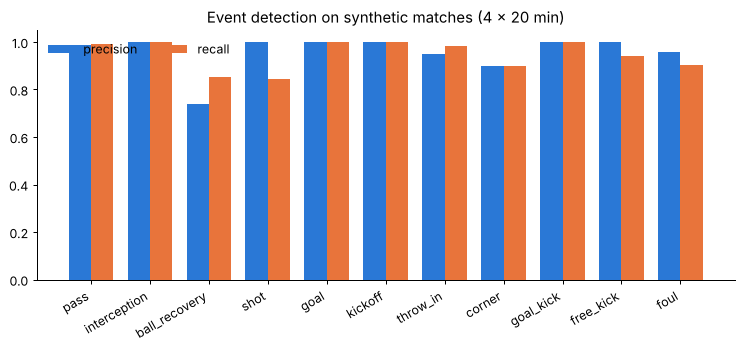

In [5]:
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(len(agg)); w = 0.38
ax.bar(x - w/2, agg.precision, w, label="precision", color="#2a78d6")
ax.bar(x + w/2, agg.recall, w, label="recall", color="#e8743b")
ax.set_xticks(x, agg.index, rotation=30, ha="right"); ax.set_ylim(0, 1.05); ax.legend(frameon=False, ncol=2)
ax.set_title("Event detection on synthetic matches (4 × 20 min)");

## 3 · Robustness to perception noise
`clean` ≈ well-tuned perception; `realistic` ≈ a club stream; `hard` ≈ poor light / low resolution, IDs switching every ~30 s and goalkeepers not recognised.

In [6]:
levels = {
    "clean":     dict(noise_player_m=0.15, noise_ball_m=0.2, ball_dropout=0.03, occlusion_per_min=1),
    "realistic": dict(noise_player_m=0.4, noise_ball_m=0.5, ball_dropout=0.12, occlusion_per_min=4, fragment_s=60),
    "hard":      dict(noise_player_m=0.8, noise_ball_m=0.9, ball_dropout=0.25, occlusion_per_min=8, fragment_s=30,
                      label_goalkeepers=False),
}
res = {}
for name, kw in levels.items():
    f1s = []
    for seed in (21, 22):
        m_, r_ = run(seed=seed, period_s=600, **kw)
        f1s.append(evaluate_events(r_["events"], m_["gt_events"], TYPES).f1)
        f1s[-1]["possession_acc"] = possession_accuracy(r_["fc"], r_["possession"], m_["truth"])["frame_accuracy"]
    res[name] = pd.concat(f1s, axis=1).mean(axis=1)
rob = pd.DataFrame(res)
rob

,clean,realistic,hard
type,,,
pass,0.987,0.973,0.884
interception,0.974,0.885,0.717
ball_recovery,0.888,0.797,0.413
shot,0.893,0.855,0.736
goal,1.000,1.000,0.967
kickoff,1.000,1.000,0.868
throw_in,1.000,1.000,0.869
corner,1.000,1.000,1.000
goal_kick,0.944,0.944,1.000


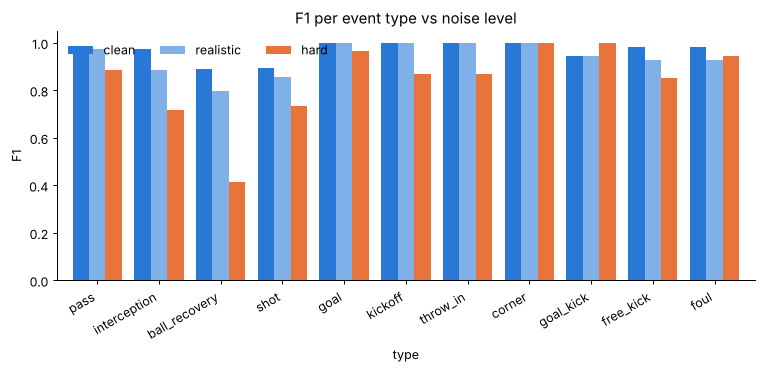

In [7]:
ax = rob.drop("possession_acc").plot.bar(figsize=(10, 3.6), color=["#2a78d6", "#7fb0e8", "#e8743b"], width=0.8)
ax.set_ylim(0, 1.05); ax.set_ylabel("F1"); ax.set_title("F1 per event type vs noise level"); ax.legend(frameon=False, ncol=3)
plt.xticks(rotation=30, ha="right");

## 4 · Sensitivity to the control radius (`possession.control_radius_m`)

In [8]:
sens = []
for rad in (0.8, 1.2, 1.5, 2.0, 2.5):
    cfg = load_config(possession=dict(control_radius_m=rad, duel_radius_m=rad))
    m_, r_ = run(seed=31, period_s=600, cfg=cfg, **levels["realistic"])
    s = evaluate_events(r_["events"], m_["gt_events"], ["pass", "interception", "shot"])
    sens.append(dict(radius=rad, pass_f1=s.loc["pass", "f1"], interception_f1=s.loc["interception", "f1"],
                     shot_f1=s.loc["shot", "f1"],
                     possession_acc=possession_accuracy(r_["fc"], r_["possession"], m_["truth"])["frame_accuracy"]))
sens = pd.DataFrame(sens).set_index("radius"); sens

,pass_f1,interception_f1,shot_f1,possession_acc
radius,,,,
0.8,0.938,0.808,0.743,0.970
1.2,0.962,0.902,0.800,0.977
1.5,0.970,0.920,0.800,0.979
2.0,0.965,0.885,0.778,0.982
2.5,0.962,0.863,0.778,0.984


## 5 · Evaluating on a real match
1. Annotate the events you care about while watching (e.g. in a spreadsheet): `t` (video seconds), `type`
   (pass, shot, goal, corner, throw_in, free_kick, foul, …), `team` (0/1 as in `team_stats.csv`).
2. Save as `data/annotations/events_<match>.csv`, then:

```python
gt = pd.read_csv(ROOT / "data/annotations/events_match1.csv")
pred = pd.read_csv(ROOT / "outputs/match1/events.csv")
evaluate_events(pred, gt)
```
Start with goals, shots, corners and throw-ins for one half — 45 minutes of annotation is enough to tune the rules.

**Caveat** — synthetic scores are an *upper bound*: the generator is simpler than real football (no aerial balls,
no deflections, no crowding at set pieces). Their value is to catch regressions and to compare rule variants.